In [1]:
# Mount Google Drive (optional: for saving models)
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
pip install torch==2.1.2 torchvision==0.16.2 torchaudio==2.1.2 --index-url https://download.pytorch.org/whl/cpu


Looking in indexes: https://download.pytorch.org/whl/cpu


In [3]:
# Imports
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from transformers import RobertaTokenizer, RobertaModel, AdamW
from sklearn.metrics import f1_score, classification_report, confusion_matrix
from pathlib import Path
import numpy as np
import random
import os


In [123]:
from mamkit.data.datasets import MMUSEDFallacy, InputMode
from pathlib import Path
from torch.utils.data import Subset

# Define base path for data (Colab-compatible)
base_data_path = Path("/content/data")

# Load MMUSED-fallacy dataset for Task A (fallacy detection), text-only
dataset = MMUSEDFallacy(
    task_name='afd',  # 'afd' = detection, 'afc' = classification
    input_mode=InputMode.TEXT_ONLY,
    base_data_path=base_data_path
)

# Use subset for memory efficiency
subset_indices = list(range(2000))
dataset = Subset(dataset, subset_indices)


In [124]:
# Don't reuse 'dataset' immediately
full_dataset = MMUSEDFallacy(
    task_name='afd',
    input_mode=InputMode.TEXT_ONLY,
    base_data_path=base_data_path
)

subset_indices = list(range(2000))
dataset = Subset(full_dataset, subset_indices)  # This is now valid


In [130]:
from transformers import RobertaTokenizer
from torch.utils.data import DataLoader, random_split

tokenizer = RobertaTokenizer.from_pretrained('roberta-base')

def collate_fn(batch):
    texts = [sample['text'] for sample in batch]
    labels = [sample['label'] for sample in batch]

    encodings = tokenizer(texts, return_tensors='pt', padding=True, truncation=True, max_length=128)
    labels = torch.tensor(labels)

    return encodings, labels

# Use subset_dataset instead of dataset
# Split dataset into 80% train and 20% validation
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size
train_dataset, val_dataset = random_split(dataset, [train_size, val_size])

# Create DataLoaders
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False)


In [126]:
class RobertaClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.roberta = RobertaModel.from_pretrained('roberta-base')
        self.classifier = nn.Linear(self.roberta.config.hidden_size, 2)  # binary classification

    def forward(self, input_ids, attention_mask):
        outputs = self.roberta(input_ids=input_ids, attention_mask=attention_mask)
        pooled = outputs.last_hidden_state[:, 0]  # [CLS] token
        return self.classifier(pooled)

model = RobertaClassifier()


Some weights of RobertaModel were not initialized from the model checkpoint at roberta-base and are newly initialized: ['roberta.pooler.dense.bias', 'roberta.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [71]:
print("Dataloader uses:", type(dataloader.dataset))


Dataloader uses: <class 'torch.utils.data.dataset.Subset'>


In [92]:
print(type(full_dataset.data))

# If it's a list or dict, print first item
try:
    print(full_dataset.data[0])
except Exception as e:
    print("Accessing full_dataset.data[0] raised:", e)


<class 'pandas.core.frame.DataFrame'>
Accessing full_dataset.data[0] raised: 0


In [89]:
print(dir(full_dataset))


['__abstractmethods__', '__class__', '__delattr__', '__dict__', '__dir__', '__doc__', '__eq__', '__format__', '__ge__', '__getattribute__', '__getstate__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__le__', '__lt__', '__module__', '__ne__', '__new__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__sizeof__', '__slots__', '__str__', '__subclasshook__', '__weakref__', '_abc_impl', '_build_afc_context', '_build_afd_dataset', '_build_audio_data', '_get_audio_data', '_get_text_audio_data', '_get_text_data', 'add_splits', 'archive_url', 'audio_path', 'base_data_path', 'build_info_from_splits', 'clips_path', 'context_window', 'data', 'data_path', 'data_retriever', 'dataset_path', 'download_audio', 'folder_name', 'generate_clips', 'get_default_splits', 'get_mancini_2024_splits', 'get_splits', 'input_mode', 'load', 'sample_rate', 'splitters', 'task_name', 'with_context']


In [106]:
print(wrapped_dataset.df.columns)


Index(['context_paths', 'context', 'sentence', 'sentence_path', 'label',
       'dialogue_id', 'filename'],
      dtype='object')


In [136]:
import torch
from torch.utils.data import Dataset, DataLoader, random_split, Subset

# Wrap the dataset properly
class WrappedMMUSEDFallacy(Dataset):
    def __init__(self, mmused_dataset):
        self.df = mmused_dataset.data  # a pandas DataFrame

    def __getitem__(self, idx):
        row = self.df.iloc[idx]  # get row by position
        return {
            'text': row['sentence'],
            'label': row['label']
        }

    def __len__(self):
        return len(self.df)

# Wrap the full dataset correctly
wrapped_dataset = WrappedMMUSEDFallacy(full_dataset)

# Now subset it
subset_indices = list(range(2000))  # Assuming you want 2000 samples
subset_dataset = Subset(wrapped_dataset, subset_indices)

# Split dataset into 80% train and 20% validation
train_size = int(0.8 * len(subset_dataset))
val_size = len(subset_dataset) - train_size
train_dataset, val_dataset = random_split(subset_dataset, [train_size, val_size])

# Create DataLoaders for train and validation
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False)








In [149]:
print(batch)


{'text': ['But is that really the question that should be asked?', 'And the leaders sit down and they will negotiate, and they will come to agreements with people that they trust.', "I'm for the Stealth, I'm for the D-5, I'm for going ahead with the advance Cruise missile.", 'And so, we have set a standard that those loans and those grants are directed to the people who otherwise could not go to college, their family incomes were so low.', "It is working, and we're going to continue on that same line.", 'I was in Vilnius, Lithuania, Independence Square, speaking to 10,000 people in the middle of winter.', "Maryland would not extradite Willie Horton, the man who was furloughed, the murderer, because they didn't want him to be furloughed again.", 'He said, I felt so strongly about this, I went back and read the Lincoln-Douglas debates.', "And it's continuing to evolve, and it's evolving in favor of life.", 'And thanks to the Congress we now have an agricultural credit bill which is helpi

In [151]:
print(inputs)


{'input_ids': tensor([[    0,  2409,    38, 11222,  2198,     7,     5,  4780,    14,  4336,
          5076,    34,  2327,  3422,     6,     5,  4780,    14,     5,   315,
           532,   197,   517,   789,     4,     2,     1,     1,     1,     1,
             1,     1,     1,     1,     1,     1,     1,     1,     1,     1,
             1,     1,     1,     1,     1,     1,     1,     1,     1,     1,
             1,     1,     1,     1],
        [    0,  1640,   574, 35609,    43,  1437,   125,    38,  1034,    47,
           351,    75,   185,   127,   292,  2397,   409,    31,   162,     4,
             2,     1,     1,     1,     1,     1,     1,     1,     1,     1,
             1,     1,     1,     1,     1,     1,     1,     1,     1,     1,
             1,     1,     1,     1,     1,     1,     1,     1,     1,     1,
             1,     1,     1,     1],
        [    0,   133,  1761,     7,    61,     5,   270, 12859,     6,    11,
           754,     6,  1519,    13,    1

In [152]:
from sklearn.metrics import f1_score
from transformers import AdamW
import torch.nn as nn
import torch

# Setup optimizer and loss function
optimizer = AdamW(model.parameters(), lr=2e-5)
loss_fn = nn.CrossEntropyLoss()

# Move model to GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)


# Training loop with validation
for epoch in range(5):
    model.train()
    total_train_loss = 0
    for batch in train_loader:
        # Extract the text and labels
        texts = batch['text']  # A list of sentences
        labels = batch['label']  # A tensor of labels

        # Tokenize the texts
        inputs = tokenizer(texts, padding=True, truncation=True, return_tensors="pt", max_length=512)

        # Move data to device (cuda or cpu)
        inputs = {k: v.to(device) for k, v in inputs.items()}
        labels = labels.to(device)

        optimizer.zero_grad()

        # Forward pass
        outputs = model(**inputs)  # Pass inputs as model input

        # If outputs is a tensor (not an object with 'logits'), use it directly
        if isinstance(outputs, torch.Tensor):
            logits = outputs  # Directly use the tensor as logits
        else:
            logits = outputs[0]  # Otherwise, take the first item (logits)

        loss = loss_fn(logits, labels)  # Use logits for loss calculation
        loss.backward()
        optimizer.step()

        total_train_loss += loss.item()

    # Validation phase
    model.eval()
    total_val_loss = 0
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for batch in val_loader:
            # Extract the text and labels
            texts = batch['sentence']  # A list of sentences
            labels = batch['label']  # A tensor of labels

            # Tokenize the texts
            inputs = tokenizer(texts, padding=True, truncation=True, return_tensors="pt", max_length=512)

            # Move data to device (cuda or cpu)
            inputs = {k: v.to(device) for k, v in inputs.items()}
            labels = labels.to(device)

            outputs = model(**inputs)  # Pass inputs as model input

            # If outputs is a tensor (not an object with 'logits'), use it directly
            if isinstance(outputs, torch.Tensor):
                logits = outputs  # Directly use the tensor as logits
            else:
                logits = outputs[0]  # Otherwise, take the first item (logits)

            loss = loss_fn(logits, labels)  # Use logits for loss calculation
            total_val_loss += loss.item()

            preds = torch.argmax(logits, dim=1)  # Get predictions from logits
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    val_f1 = f1_score(all_labels, all_preds, average='macro')
    print(f"Epoch {epoch+1} | Train Loss: {total_train_loss:.4f} | Val Loss: {total_val_loss:.4f} | Val F1: {val_f1:.4f}")

Epoch 1 | Train Loss: 36.9145 | Val Loss: 7.4239 | Val F1: 0.4778
Epoch 2 | Train Loss: 34.2009 | Val Loss: 7.4278 | Val F1: 0.4778
Epoch 3 | Train Loss: 30.2142 | Val Loss: 6.6741 | Val F1: 0.4778
Epoch 4 | Train Loss: 23.2018 | Val Loss: 7.0884 | Val F1: 0.5303
Epoch 5 | Train Loss: 13.2401 | Val Loss: 9.9027 | Val F1: 0.5879


In [153]:
model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for batch in dataloader:
        inputs, labels = batch
        inputs = {k: v for k, v in inputs.items()}
        labels = labels

        outputs = model(**inputs)
        preds = torch.argmax(outputs, dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

print(classification_report(all_labels, all_preds))
print("Confusion Matrix:\n", confusion_matrix(all_labels, all_preds))


              precision    recall  f1-score   support

           0       0.99      1.00      0.99       288
           1       1.00      0.75      0.86        12

    accuracy                           0.99       300
   macro avg       0.99      0.88      0.93       300
weighted avg       0.99      0.99      0.99       300

Confusion Matrix:
 [[288   0]
 [  3   9]]


              precision    recall  f1-score   support

           0       0.99      1.00      0.99       288
           1       1.00      0.75      0.86        12

    accuracy                           0.99       300
   macro avg       0.99      0.88      0.93       300
weighted avg       0.99      0.99      0.99       300



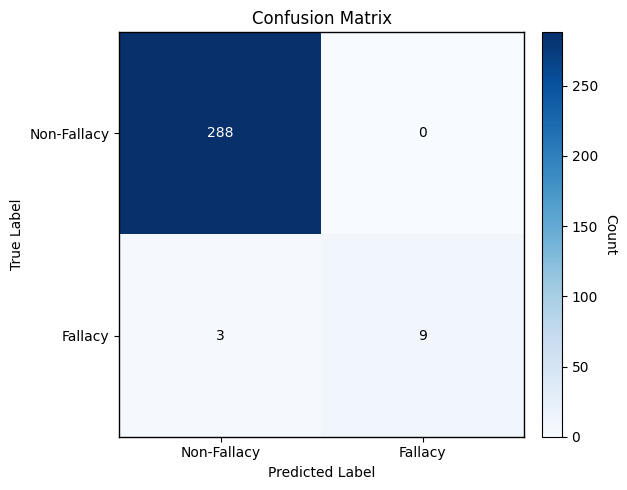

In [156]:
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix

model.eval()
all_preds, all_labels = [], []

with torch.no_grad():
    for batch in dataloader:
        inputs, labels = batch

        # Move inputs to device if you're on GPU:
        inputs = {k: v.to(device) for k, v in inputs.items()}
        labels = labels.to(device)

        outputs = model(**inputs)
        # Handle HuggingFace outputs vs raw tensor
        if hasattr(outputs, 'logits'):
            logits = outputs.logits
        elif isinstance(outputs, tuple):
            logits = outputs[0]
        else:
            logits = outputs
        preds = torch.argmax(logits, dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# 1) Print the text report
print(classification_report(all_labels, all_preds))

# 2) Compute the confusion matrix
cm = confusion_matrix(all_labels, all_preds)

# 3) Plot it
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm, cmap='Blues')

# Annotate counts
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        color = 'white' if cm[i, j] > cm.max() / 2 else 'black'
        ax.text(j, i, cm[i, j], ha='center', va='center', color=color)

# Axis labels & ticks
labels = ['Non-Fallacy', 'Fallacy']
ax.set_xticks([0, 1])
ax.set_xticklabels(labels)
ax.set_yticks([0, 1])
ax.set_yticklabels(labels)
ax.set_xlabel('Predicted Label')
ax.set_ylabel('True Label')
ax.set_title('Confusion Matrix')

# Colorbar (boxed)
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.ax.set_ylabel('Count', rotation=-90, va="bottom")

# Draw a black box around
for spine in ax.spines.values():
    spine.set_edgecolor('black')
    spine.set_linewidth(1)

plt.tight_layout()
plt.show()


In [155]:
save_path = "/content/drive/MyDrive/fallacy_project/text_only/task_a_model.pt"
torch.save(model.state_dict(), save_path)
print(f"Model saved to {save_path}")


Model saved to /content/drive/MyDrive/fallacy_project/text_only/task_a_model.pt
